In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys
REPO = '/content/sar-flood-unet'
if os.path.exists(REPO):
    !git -C {REPO} pull -q          # already cloned this session: fetch latest
else:
    !git clone -q https://github.com/Ronnelpabalan/sar-flood-unet.git {REPO}
sys.path.insert(0, REPO)            # let Python find the src/ folder

from src.metrics import valid_mask, MetricAccumulator, metrics_from_counts
print('metrics module loaded')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
metrics module loaded


In [2]:
import numpy as np
import pandas as pd
import rasterio
from tqdm.auto import tqdm

DATA_DIR = '/content/drive/MyDrive/sen1floods11'
SPLITS = ['train', 'valid', 'test', 'bolivia']

def load_chip(cid):
    """Return (s1, label): s1 is (2, 512, 512) float32 [VV, VH] in dB, label is (512, 512) int16."""
    with rasterio.open(f'{DATA_DIR}/S1Hand/{cid}_S1Hand.tif') as src:
        s1 = src.read().astype('float32')
    with rasterio.open(f'{DATA_DIR}/LabelHand/{cid}_LabelHand.tif') as src:
        lab = src.read(1)
    return s1, lab

data = {}
for split in SPLITS:
    df = pd.read_csv(f'{DATA_DIR}/splits/flood_{split}_data.csv', header=None, names=['s1', 'label'])
    data[split] = [(f.replace('_S1Hand.tif', ''), *load_chip(f.replace('_S1Hand.tif', '')))
                   for f in tqdm(df['s1'], desc=split)]
print({s: len(v) for s, v in data.items()})

train:   0%|          | 0/252 [00:00<?, ?it/s]

valid:   0%|          | 0/89 [00:00<?, ?it/s]

test:   0%|          | 0/90 [00:00<?, ?it/s]

bolivia:   0%|          | 0/15 [00:00<?, ?it/s]

{'train': 252, 'valid': 89, 'test': 90, 'bolivia': 15}


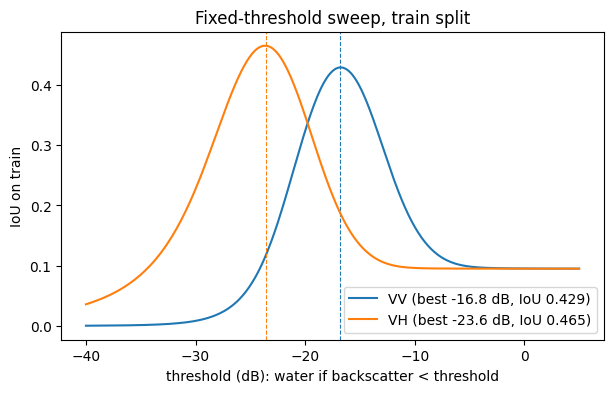

Chosen thresholds: {'VV': -16.8, 'VH': -23.6}


In [3]:
import matplotlib.pyplot as plt

EDGES = np.round(np.arange(-40, 5.001, 0.1), 1)            # candidate thresholds, 0.1 dB steps
BINS = np.concatenate([[-np.inf], EDGES, [np.inf]])

def sweep_thresholds(split, band):
    """IoU and F1 for 'water if value < t' at every t in EDGES, pooled over a split."""
    w_hist = np.zeros(len(BINS) - 1)
    l_hist = np.zeros(len(BINS) - 1)
    for cid, s1, lab in data[split]:
        v = valid_mask(lab, s1)
        x, y = s1[band][v], lab[v]
        w_hist += np.histogram(x[y == 1], BINS)[0]
        l_hist += np.histogram(x[y == 0], BINS)[0]
    tp = np.cumsum(w_hist)[:len(EDGES)]      # water pixels below each threshold
    fp = np.cumsum(l_hist)[:len(EDGES)]      # land pixels below each threshold
    fn = w_hist.sum() - tp                   # water pixels at or above the threshold
    return pd.DataFrame({'threshold': EDGES,
                         'iou': tp / (tp + fp + fn),
                         'f1': 2 * tp / (2 * tp + fp + fn)})

best_t = {}
fig, ax = plt.subplots(figsize=(7, 4))
for band, name in [(0, 'VV'), (1, 'VH')]:
    sw = sweep_thresholds('train', band)
    best = sw.loc[sw['iou'].idxmax()]
    best_t[name] = float(best['threshold'])
    ax.plot(sw['threshold'], sw['iou'], label=f'{name} (best {best.threshold:.1f} dB, IoU {best.iou:.3f})')
    ax.axvline(best['threshold'], ls='--', lw=0.8, color=ax.lines[-1].get_color())
ax.set_xlabel('threshold (dB): water if backscatter < threshold')
ax.set_ylabel('IoU on train')
ax.set_title('Fixed-threshold sweep, train split')
ax.legend(); plt.show()
print('Chosen thresholds:', best_t)

In [5]:
all_nan = [(split, cid, int((lab != -1).sum()))
           for split in SPLITS for cid, s1, lab in data[split]
           if np.isnan(s1[0]).all()]
print(f'{len(all_nan)} chips with no VV data:')
for split, cid, n_labelled in all_nan:
    print(f'  {split:8s} {cid:22s} labelled pixels: {n_labelled:,}')

1 chips with no VV data:
  test     Paraguay_34417         labelled pixels: 50,026


In [9]:
test_table = results[results['split'] == 'test'].drop(columns='split').set_index('method')
display(test_table)

results.to_csv('/content/baseline_metrics.csv', index=False)
from google.colab import files
files.download('/content/baseline_metrics.csv')

,iou,f1,precision,recall,accuracy
method,,,,,
Otsu VV (per chip),0.211,0.349,0.230,0.727,0.666
Fixed VV < -16.8 dB,0.464,0.634,0.774,0.536,0.924
Fixed VH < -23.6 dB,0.533,0.695,0.747,0.650,0.930


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
from skimage.filters import threshold_otsu

def predict_otsu(s1, band):
    x = s1[band]
    vals = x[~np.isnan(x)]
    if vals.size == 0:                       # chip has no SAR data: nothing to classify
        return np.zeros(x.shape, dtype=bool) # (all its pixels are excluded by valid_mask anyway)
    t = threshold_otsu(vals)                 # threshold chosen per chip, from SAR only (no labels)
    return x < t

methods = {
    'Otsu VV (per chip)':           lambda s1: predict_otsu(s1, 0),
    f'Fixed VV < {best_t["VV"]} dB': lambda s1: predict_fixed(s1, 0, best_t['VV']),
    f'Fixed VH < {best_t["VH"]} dB': lambda s1: predict_fixed(s1, 1, best_t['VH']),
}

rows = []
for method, fn in methods.items():
    for split in ['train', 'valid', 'test', 'bolivia']:
        acc = MetricAccumulator()
        for cid, s1, lab in data[split]:
            acc.add(fn(s1), lab, valid_mask(lab, s1))
        rows.append({'method': method, 'split': split, **acc.compute()})

results = pd.DataFrame(rows).round(3)
results.pivot(index='method', columns='split', values='iou')[['train', 'valid', 'test', 'bolivia']]

split,train,valid,test,bolivia
method,,,,
Fixed VH < -23.6 dB,0.465,0.493,0.533,0.535
Fixed VV < -16.8 dB,0.429,0.465,0.464,0.436
Otsu VV (per chip),0.166,0.188,0.211,0.350


In [8]:
otsu = pd.DataFrame([{'chip': cid,
                      'otsu_vv': threshold_otsu(s1[0][~np.isnan(s1[0])]),
                      'has_water': bool((lab == 1).any())}
                     for cid, s1, lab in data['test']
                     if not np.isnan(s1[0]).all()])      # skip chips with no SAR data

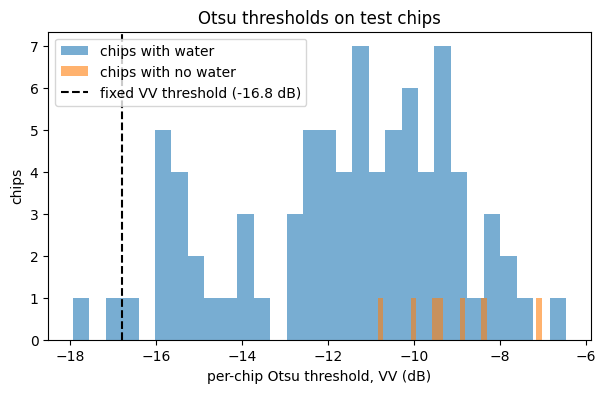

           count  mean  std   min   25%   50%  75%  max
has_water                                              
False        7.0  -9.1  1.2 -10.8  -9.8  -9.4 -8.6 -7.0
True        82.0 -11.6  2.5 -17.9 -12.8 -11.3 -9.6 -6.5


In [10]:
otsu = pd.DataFrame([{'chip': cid,
                      'otsu_vv': threshold_otsu(s1[0][~np.isnan(s1[0])]),
                      'has_water': bool((lab == 1).any())}
                     for cid, s1, lab in data['test']
                     if not np.isnan(s1[0]).all()])      # skip chips with no SAR data

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(otsu.loc[otsu.has_water, 'otsu_vv'], bins=30, alpha=0.6, label='chips with water')
ax.hist(otsu.loc[~otsu.has_water, 'otsu_vv'], bins=30, alpha=0.6, label='chips with no water')
ax.axvline(best_t['VV'], color='k', ls='--', label=f'fixed VV threshold ({best_t["VV"]} dB)')
ax.set_xlabel('per-chip Otsu threshold, VV (dB)'); ax.set_ylabel('chips')
ax.set_title('Otsu thresholds on test chips'); ax.legend(); plt.show()
print(otsu.groupby('has_water')['otsu_vv'].describe().round(1))

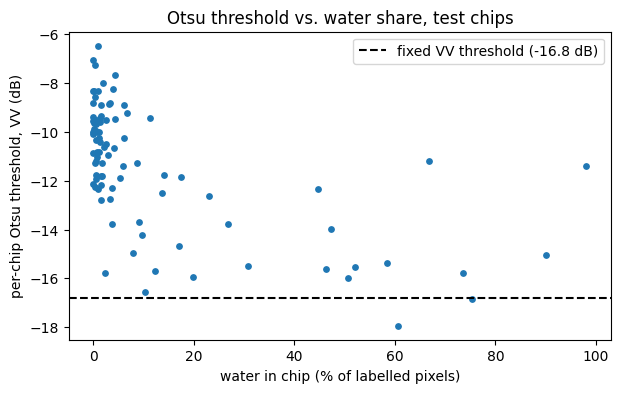

In [11]:
water_pct = {cid: 100 * (lab == 1).sum() / max((lab != -1).sum(), 1) for cid, s1, lab in data['test']}
otsu['water_%'] = otsu['chip'].map(water_pct)

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(otsu['water_%'], otsu['otsu_vv'], s=15)
ax.axhline(best_t['VV'], color='k', ls='--', label=f'fixed VV threshold ({best_t["VV"]} dB)')
ax.set_xlabel('water in chip (% of labelled pixels)')
ax.set_ylabel('per-chip Otsu threshold, VV (dB)')
ax.set_title('Otsu threshold vs. water share, test chips'); ax.legend(); plt.show()